# Proyecto final · Fase 4 — Semana 3

## Visualización y comunicación de resultados

**MCDI500 · Programación para la Ciencia de Datos · Grupo 8**

**Caso: Relación comodidades, capacidad y ubicacion de alojamientos Airbnb con precios y ocupación estimada (Inside Airbnb, captura 23-09-2026)**

---

Este cuaderno cierra el proyecto. No vuelve a limpiar ni a transformar: **recibe los cuatro artefactos que dejó la Fase 3**, construye una copia con las unidades originales (pesos, noches, huéspedes) y responde con figuras la pregunta del proyecto:

> ¿Qué relación existe entre las comodidades, la capacidad y la ubicación de los alojamientos completos de Airbnb Santiago y su precio y ocupación anual estimada?

| Fase | Cuaderno | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/S1_F1_Definicion.ipynb` | Problema, preguntas, entorno y ficha del conjunto |
| F2 | `F2/S1_F2_Preprocesamiento.ipynb` | Decisiones de limpieza justificadas con cifras |
| F3 | `F3/S2_F3_NucleoAlgoritmico_Eficiencia_POO.ipynb` | Pipeline en clases y cuatro artefactos en `data/processed/` |
| **F4** | **este cuaderno** | Figuras, hallazgos y evidencia para el informe y el video |

**Cómo usarlo.** Ejecuten antes F1, F2 y F3, en ese orden, o verifiquen que existan los cuatro archivos de `data/processed/`. Luego, *Restart & Run All*. Si faltan los artefactos, el cuaderno se detiene con un mensaje claro.

## 1. Entorno y ubicación del proyecto

Se comprueba que el cuaderno corra en el entorno virtual del proyecto y que encuentre la raíz aunque Jupyter lo abra dentro de `F4/`.

In [11]:
import os
import sys
import json
from datetime import date
from pathlib import Path

import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
np.random.seed(SEMILLA)

print("Entorno    :", "virtual" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")   #Se eliminó print("Python     :", sys.executable), Ya que el profe pidió elimninar
print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

Entorno    : virtual
pandas     : 3.1.1
NumPy      : 2.5.4
matplotlib : 3.11.2


**Buscamos raíz del proyecto** y la cargamos

In [12]:
def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto aunque Jupyter abra el cuaderno dentro de F4/."""
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

# La raíz debe estar en la ruta de búsqueda para importar src/, igual que en la F3
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import comunicacion as com
from src.medicion import medir

# Rutas relativas a la raíz: no muestran la carpeta personal de nadie
print("Raíz del proyecto :", RAIZ.name)
print("Artefactos de F3  :", DIR_PROCESADO.relative_to(RAIZ))
print("Figuras de F4     :", DIR_FIGURAS.relative_to(RAIZ))

Raíz del proyecto : grupo_8_magister_mcdi500
Artefactos de F3  : data\processed
Figuras de F4     : F4\figuras


### Estilo de las figuras

Se define una sola vez. El color tiene **función**, no decoración: el granate marca el dato que sostiene el hallazgo; el azul, la comparación; y el gris, el contexto. Las cifras usan formato chileno: punto de miles y coma decimal.

In [13]:
GRANATE = "#AC212E"     # el dato que se quiere destacar
AZUL = "#06304A"        # comparación
TINTA = "#0A1526"       # texto
HIELO = "#D7E3EE"       # fondos y bandas de referencia
GRIS = "#8A94A0"        # contexto, lo secundario

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (8, 4.4),
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10.5,
    "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "legend.frameon": False,
    "font.size": 10,
    "text.parse_math": False,   # para que el signo $ se muestre tal cual
})

FUENTE = "Fuente: Inside Airbnb, Santiago, captura 23-09-2026. Alojamientos completos (n = {n})."


def nota_fuente(figura, n, extra=""):
    """Escribe la fuente bajo la figura, debajo de la etiqueta del eje x."""
    figura.text(0.01, -0.07, FUENTE.format(n=miles(n)) + (" " + extra if extra else ""),
                fontsize=8, color=GRIS, ha="left", va="top")


def pct(proporcion, decimales=1):
    """0.176 -> '17,6 %'"""
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    """14758 -> '14.758'"""
    return f"{int(round(numero)):,}".replace(",", ".")


def clp(numero):
    """60000 -> '$60.000'"""
    return "$" + miles(numero)

---
## 2. Lo que la Fase 3 entregó

### 2.1 Carga de los cuatro artefactos

`cargar_artefactos` está en `src/comunicacion.py`. Si falta un archivo, se detiene y dice qué cuaderno ejecutar: no hay una alternativa silenciosa.

| Artefacto | Contenido |
|---|---|
| `entrenamiento_f3.csv` | 80 % de los alojamientos, ya transformados |
| `prueba_f3.csv` | 20 % restante, transformado con lo aprendido en entrenamiento |
| `parametros_f3.csv` | Lo que aprendió cada paso del pipeline (medianas, RIC, categorías), en JSON |
| `diccionario_f3.csv` | Nombre, tipo y descripción de cada columna |

In [14]:
artefactos = com.cargar_artefactos(DIR_PROCESADO)

for nombre, tabla in artefactos.items():
    print(f"{nombre:<14} {tabla.shape[0]:>6} filas x {tabla.shape[1]:>2} columnas")

entrenamiento   11788 filas x 50 columnas
prueba           2970 filas x 50 columnas
parametros         24 filas x  3 columnas
diccionario        50 filas x  4 columnas


### 2.2 Verificar el contrato antes de usarlo

La Fase 3 prometió un esquema. Antes de graficar se comprueba que lo cumplió: mismas columnas en entrenamiento y prueba, en el orden del diccionario, sin nulos, y con las siete variables escaladas con `RobustScaler` en el entrenamiento, es decir, con **mediana 0 y rango intercuartílico 1**.

In [15]:
entrenamiento = artefactos["entrenamiento"]
prueba = artefactos["prueba"]
diccionario = artefactos["diccionario"]
parametros = com.leer_parametros(artefactos["parametros"])   # JSON -> diccionarios

# Las variables escaladas se leen de los parámetros guardados, no se escriben a mano
ESCALADAS = [p[len("EscaladorRobusto("):-1] for p in parametros if p.startswith("EscaladorRobusto(")]
PRECIO, OCUP = "price", "estimated_occupancy_l365d"
ric = entrenamiento[ESCALADAS].quantile(0.75) - entrenamiento[ESCALADAS].quantile(0.25)

assert list(entrenamiento.columns) == list(diccionario["columna"]), "El entrenamiento no sigue el diccionario"
assert list(prueba.columns) == list(entrenamiento.columns), "Entrenamiento y prueba difieren en esquema"
assert entrenamiento.isna().sum().sum() == 0 and prueba.isna().sum().sum() == 0, "Hay nulos en los artefactos"
assert np.allclose(entrenamiento[ESCALADAS].median(), 0), "Las escaladas no tienen mediana 0"
assert np.allclose(ric, 1), "Las escaladas no tienen RIC 1"

print("Contrato de la Fase 3: cumplido")
print("Variables escaladas :", ESCALADAS)
print("Pasos registrados   :", len(parametros))
print(f"Mediana de 'latitude' en prueba (escalada): {prueba['latitude'].median():+.3f}  "
      "(no es 0: el escalador no aprendió de prueba)")

Contrato de la Fase 3: cumplido
Variables escaladas : ['accommodates', 'latitude', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'n_comodidades']
Pasos registrados   : 24
Mediana de 'latitude' en prueba (escalada): -0.030  (no es 0: el escalador no aprendió de prueba)


### 2.3 La copia interpretable

Un gráfico con la capacidad en "rangos intercuartílicos" no se entiende. Para comunicar se construye una **copia** con las unidades originales, aplicando la inversa exacta del escalado con los parámetros que aprendió la Fase 3:

$$x = z \cdot \text{RIC}_{\text{entrenamiento}} + \text{mediana}_{\text{entrenamiento}}$$

Además, las 30 columnas `comuna_` vuelven a ser una sola columna con el nombre de la comuna, y `superhost_f`/`superhost_t` vuelven a ser `host_is_superhost`. Los artefactos de la Fase 3 **no se modifican**: la copia es solo para comunicar.

In [16]:
entrenamiento_legible = com.copia_interpretable(entrenamiento, parametros)
prueba_legible = com.copia_interpretable(prueba, parametros)

# Para describir se usan ambos conjuntos: describir no es entrenar un modelo, así que juntarlos
# no produce fuga de información. Se guarda de qué conjunto viene cada fila para la sección de estabilidad.
legible = pd.concat([entrenamiento_legible.assign(conjunto="entrenamiento"),
                     prueba_legible.assign(conjunto="prueba")], ignore_index=True)

print(f"Copia interpretable: {miles(legible.shape[0])} filas x {legible.shape[1]} columnas")
legible[[PRECIO, OCUP, "accommodates", "bedrooms", "n_comodidades",
         "neighbourhood_cleansed", "host_is_superhost"]].describe(include="all").round(1)

Copia interpretable: 14.758 filas x 21 columnas


,price,estimated_occupancy_l365d,accommodates,bedrooms,n_comodidades,neighbourhood_cleansed,host_is_superhost
count,14758.0,14758.0,14758.0,14758.0,14758.0,14758,14758
unique,NaN,NaN,NaN,NaN,NaN,30,2
top,NaN,NaN,NaN,NaN,NaN,Santiago,f
freq,NaN,NaN,NaN,NaN,NaN,6130,7405
mean,91398.6,87.9,3.4,1.4,32.2,NaN,NaN
std,122458.8,87.0,1.7,0.8,15.1,NaN,NaN
min,9500.0,0.0,1.0,0.0,0.0,NaN,NaN
25%,44697.7,12.0,2.0,1.0,21.0,NaN,NaN
50%,60000.0,60.0,3.0,1.0,34.0,NaN,NaN
75%,87433.8,150.0,4.0,2.0,43.0,NaN,NaN


### 2.4 La verificación que más rinde: contra el archivo original

Comprobar la copia con el mismo código que la produjo sería circular. La verificación independiente se hace contra el **archivo original** de `data/raw/`: se aplican con pandas simple las reglas documentadas en F2 (alojamientos completos, objetivos sin faltantes, precio ≤ 10 millones, dormitorios ≤ huéspedes). Si la inversa es correcta, deben aparecer exactamente los mismos valores de precio, ocupación, capacidad y dormitorios, y las mismas frecuencias de comunas y superhost.

Los dormitorios son la excepción esperada: la Fase 3 imputó 2 faltantes con la mediana del entrenamiento, así que deben coincidir **después** de aplicar esa misma imputación.

El archivo original no se versiona (contiene datos personales de anfitriones). Si no está, la celda lo avisa y el cuaderno continúa.|

In [17]:
DIR_CRUDO = RAIZ / "data" / "raw"
archivo_original = DIR_CRUDO / "datasetairbnb.csv"

if not archivo_original.exists():
    print("AVISO: no está data/raw/datasetairbnb.csv; se omite la verificación contra el original.")
else:
    o = pd.read_csv(archivo_original)
    # Reglas de F2 aplicadas con pandas simple, sin las clases del pipeline
    o = o[o["room_type"] == "Entire home/apt"].copy()
    o[PRECIO] = pd.to_numeric(o[PRECIO].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
    o = o.dropna(subset=[PRECIO, OCUP])
    o["bedrooms"] = o["bedrooms"].fillna(parametros["ImputadorFlexible(bedrooms)"]["valor"])
    o["accommodates"] = o["accommodates"].fillna(parametros["ImputadorFlexible(accommodates)"]["valor"])
    o = o[(o[PRECIO] <= 10_000_000) & (o["bedrooms"] <= o["accommodates"])]

    def mismos_valores(col):
        return np.allclose(np.sort(o[col]), np.sort(legible[col]))

    def mismas_frecuencias(col, relleno=None):
        orig = o[col].fillna(relleno) if relleno else o[col]
        return orig.value_counts().sort_index().equals(legible[col].value_counts().sort_index())

    comprobaciones = {
        "Mismo número de alojamientos": len(o) == len(legible),
        "Precio idéntico al original": mismos_valores(PRECIO),
        "Ocupación idéntica al original": mismos_valores(OCUP),
        "Capacidad idéntica al original": mismos_valores("accommodates"),
        "Dormitorios idénticos tras la imputación de F3": mismos_valores("bedrooms"),
        "Frecuencias de comunas": mismas_frecuencias("neighbourhood_cleansed"),
        "Frecuencias de superhost": mismas_frecuencias("host_is_superhost", relleno="f"),
    }
    for control, resultado in comprobaciones.items():
        print(f"[{'OK' if resultado else 'FALLA'}] {control}")
    assert all(comprobaciones.values()), "La copia interpretable no coincide con el original"

[OK] Mismo número de alojamientos
[OK] Precio idéntico al original
[OK] Ocupación idéntica al original
[OK] Capacidad idéntica al original
[OK] Dormitorios idénticos tras la imputación de F3
[OK] Frecuencias de comunas
[OK] Frecuencias de superhost


---
## 3. La pregunta del proyecto, respondida con figuras

La pregunta tiene tres variables explicativas (ubicación, capacidad y comodidades) y dos resultados (precio y ocupación). Se responde con **tres figuras de tipos distintos**, ordenadas en tres movimientos:

| Movimiento | Figura | Tipo de gráfico | Pregunta |
|---|---|---|---|
| Contexto | 1 · Ubicación | Barras horizontales | ¿Dónde son más caros y más ocupados los alojamientos? |
| Contraste | 2 · Capacidad | Cajas | ¿Los alojamientos más grandes cobran más y se ocupan más? |
| Resolución | 3 · Comodidades | Líneas | ¿Los alojamientos con más comodidades se ocupan más, también dentro de una misma comuna? |
| Síntesis | 4 · Capacidad y comodidades | Mapa de calor | ¿Qué combinación se asocia a la mayor ocupación? |

### 3.1 Decisiones antes de graficar

- **Medianas y rango intercuartílico (RIC)**, no medias, porque precio y ocupación son muy asimétricos.
- **Ocupación:** es una estimación a partir de las reseñas, con muchos ceros y un tope. Las figuras usan solo los alojamientos con ocupación mayor que 0, y el porcentaje de ceros se informa aparte.
- **Comunas con menos de 30 alojamientos** se agrupan en "Otras comunas", porque con tan pocos casos su mediana no es estable.
- **Capacidad** se agrupa en tramos ordenados; los grupos de 7 y más huéspedes se juntan porque son pocos.

In [18]:
TOPE = legible[OCUP].max()
ceros = (legible[OCUP] == 0).mean()
en_tope = (legible[OCUP] == TOPE).mean()

# Ocupación solo de los alojamientos activos: NaN cuando la ocupación es 0
legible["ocupacion_positiva"] = legible[OCUP].where(legible[OCUP] > 0)

# Comunas pequeñas -> "Otras comunas"
MIN_COMUNA = 30
conteo = legible["neighbourhood_cleansed"].value_counts()
pequenas = conteo[conteo < MIN_COMUNA].index
legible["comuna"] = legible["neighbourhood_cleansed"].where(
    ~legible["neighbourhood_cleansed"].isin(pequenas), f"Otras comunas ({len(pequenas)})")

# Capacidad en tramos ordenados
legible["capacidad"] = pd.cut(legible["accommodates"], bins=[0, 1, 2, 3, 4, 5, 6, 8, np.inf],
                              labels=["1", "2", "3", "4", "5", "6", "7–8", "9 o más"])

print(f"Precio      : mediana {clp(legible[PRECIO].median())} | media {clp(legible[PRECIO].mean())}")
print(f"Ocupación   : mediana {miles(legible[OCUP].median())} noches/año | tope {miles(TOPE)} noches")
print(f"Ocupación 0 : {pct(ceros)} de los alojamientos")
print(f"En el tope  : {pct(en_tope)} de los alojamientos")
print(f"Comunas con menos de {MIN_COMUNA} alojamientos: {len(pequenas)} "
      f"(suman {miles(conteo[pequenas].sum())}) -> se agrupan en 'Otras comunas'")


def resumen(df, grupo, valor):
    """n, mediana y cuartiles de una variable por grupo: la tabla detrás de cada figura."""
    g = df.groupby(grupo, observed=True)[valor]
    return pd.DataFrame({"n": g.size(), "mediana": g.median(),
                         "q1": g.quantile(0.25), "q3": g.quantile(0.75)})


figuras = {}   # aquí se guardan las figuras para la sección de persistencia

Precio      : mediana $60.000 | media $91.399
Ocupación   : mediana 60 noches/año | tope 255 noches
Ocupación 0 : 17,6 % de los alojamientos
En el tope  : 10,5 % de los alojamientos
Comunas con menos de 30 alojamientos: 12 (suman 120) -> se agrupan en 'Otras comunas'


**Lectura.** La media del precio ($91.399) supera en más de 50 % a la mediana ($60.000): unos pocos alojamientos muy caros arrastran la media hacia arriba, y por eso se comparan medianas. El 17,6 % de los alojamientos tiene ocupación 0 y el 10,5 % está en el tope de 255 noches, así que la ocupación no se comporta como una variable continua.

### Figura 1 · Contexto: precio y ocupación por comuna

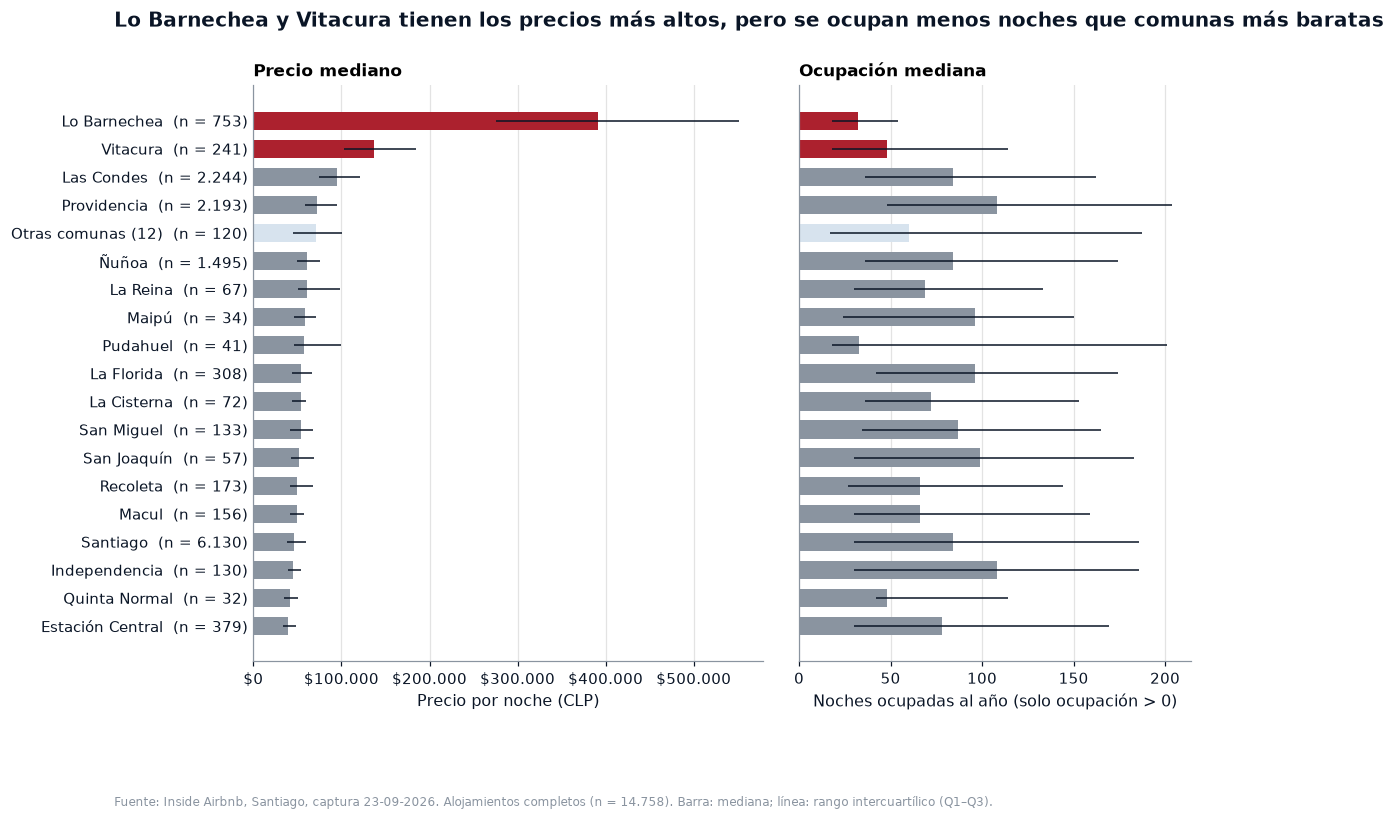

,n,precio_mediano,ocupacion_mediana,pct_cero
comuna,,,,
Lo Barnechea,753,391834.00,32.0,0.26
Vitacura,241,136666.67,48.0,0.32
Las Condes,2244,95000.00,84.0,0.14
Providencia,2193,72550.00,108.0,0.14
Otras comunas (12),120,70882.00,60.0,0.37
Ñuñoa,1495,61169.00,84.0,0.12
La Reina,67,61000.00,69.0,0.34
Maipú,34,59000.00,96.0,0.26
Pudahuel,41,57356.00,33.0,0.37


In [19]:
precio_c = resumen(legible, "comuna", PRECIO)
ocup_c = resumen(legible, "comuna", "ocupacion_positiva")
ocup_c["pct_cero"] = legible.groupby("comuna")[OCUP].apply(lambda s: (s == 0).mean())

# Orden de menor a mayor precio: en barras horizontales, la más cara queda arriba
orden = precio_c.sort_values("mediana").index
precio_c, ocup_c = precio_c.loc[orden], ocup_c.loc[orden]

# Color con función: granate para las 2 comunas más caras, gris para el resto
reales = precio_c.drop(index=[c for c in orden if c.startswith("Otras")])
destacadas = list(reales.sort_values("mediana", ascending=False).index[:2])
colores = [GRANATE if c in destacadas else (HIELO if c.startswith("Otras") else GRIS) for c in orden]
y = np.arange(len(orden))

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 6.8), sharey=True,
                               gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.08})

izq.barh(y, precio_c["mediana"], height=0.65, color=colores)
izq.hlines(y, precio_c["q1"], precio_c["q3"], color=TINTA, linewidth=1)       # RIC
izq.set_yticks(y, [f"{c}  (n = {miles(n)})" for c, n in zip(orden, precio_c["n"])])
izq.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: clp(v)))
izq.set_xlabel("Precio por noche (CLP)")
izq.set_title("Precio mediano", fontsize=11)

der.barh(y, ocup_c["mediana"], height=0.65, color=colores)
der.hlines(y, ocup_c["q1"], ocup_c["q3"], color=TINTA, linewidth=1)
der.set_xlabel("Noches ocupadas al año (solo ocupación > 0)")
der.set_title("Ocupación mediana", fontsize=11)

for eje in (izq, der):
    eje.grid(axis="x", alpha=0.35)
    eje.set_axisbelow(True)
    eje.tick_params(axis="y", length=0)

# El título dice el hallazgo; los nombres salen de los datos, no se escriben a mano
a, b = destacadas
fig.suptitle(f"{a} y {b} tienen los precios más altos, pero se ocupan menos noches que "
             f"comunas más baratas", x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA)
nota_fuente(fig, len(legible), "Barra: mediana; línea: rango intercuartílico (Q1–Q3).")
plt.show()
figuras["fig1_ubicacion"] = fig

# La tabla de la que sale la figura: de aquí se toman las cifras del informe
tabla_fig1 = precio_c[["n", "mediana"]].rename(columns={"mediana": "precio_mediano"}).join(
    ocup_c[["mediana", "pct_cero"]].rename(columns={"mediana": "ocupacion_mediana"}))
tabla_fig1.sort_values("precio_mediano", ascending=False).round(2)

**Qué muestra.** La mediana del precio por noche y de la ocupación (solo alojamientos con ocupación > 0) en cada comuna, con su rango intercuartílico y el número de alojamientos.

**Qué se infiere.** El precio se asocia fuertemente a la ubicación: Lo Barnechea ($391.834) cobra unas 8,4 veces lo que Santiago ($46.577), la comuna con más oferta (6.130 alojamientos). Pero la ocupación no sigue al precio: Lo Barnechea y Vitacura tienen las medianas más bajas (32 y 48 noches) y más alojamientos con ocupación 0 (26 % y 32 %). Providencia e Independencia, con precios intermedios, llegan a 108 noches.

**Qué límite tiene.** Es precio publicado, no pagado, y la ocupación es estimada. Parte de la diferencia de Lo Barnechea puede deberse a que tiene alojamientos más grandes, lo que se revisa en la Figura 2.

**Cómo aporta al relato.** Es el contexto: el precio varía mucho según la comuna, y las comunas más caras no son las más demandadas.

### Figura 2 · Contraste: precio y ocupación según capacidad

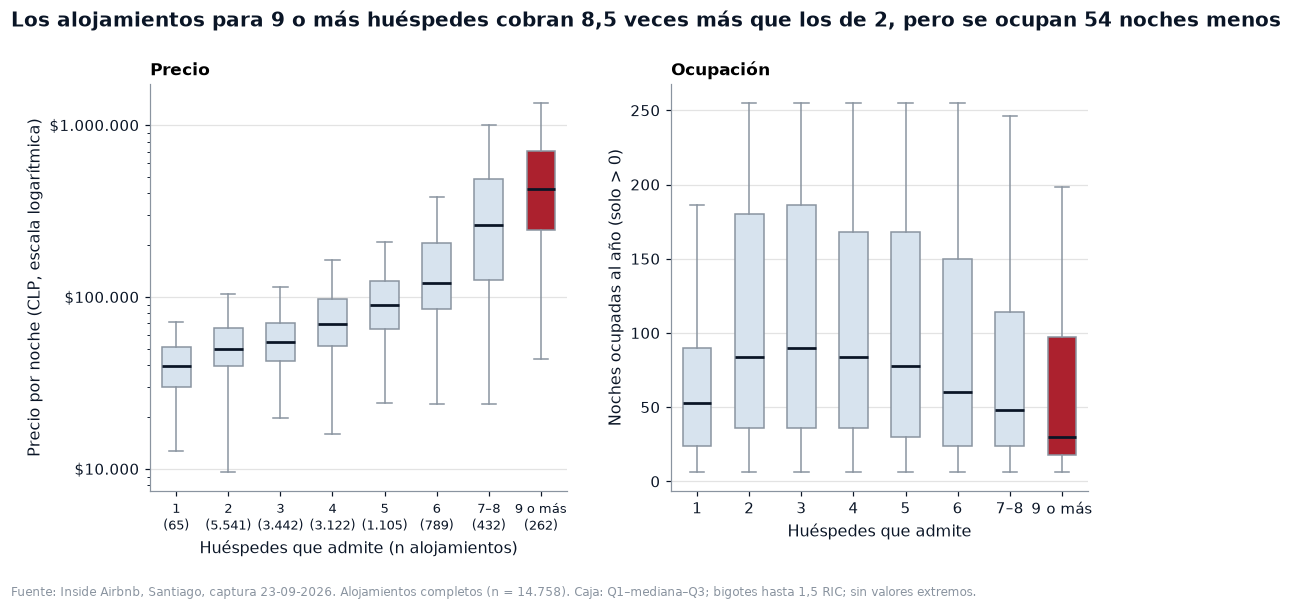

,n,precio_mediano,ocupacion_mediana,pct_cero
capacidad,,,,
1,65,39486.00,53.0,0.45
2,5541,49767.00,84.0,0.18
3,3442,54913.25,90.0,0.15
4,3122,69755.50,84.0,0.19
5,1105,89000.00,78.0,0.15
6,789,120400.00,60.0,0.18
7–8,432,262479.00,48.0,0.23
9 o más,262,422366.75,30.0,0.25


In [20]:
grupos = list(legible["capacidad"].cat.categories)
n_cap = legible["capacidad"].value_counts().reindex(grupos)
# Color con función: granate para el grupo que sostiene el contraste (9 o más huéspedes)
colores = [GRANATE if g == grupos[-1] else HIELO for g in grupos]

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"wspace": 0.25})

# El mismo gráfico de cajas para las dos variables: precio y ocupación positiva
for eje, columna in [(izq, PRECIO), (der, "ocupacion_positiva")]:
    datos = [legible.loc[legible["capacidad"] == g, columna].dropna() for g in grupos]
    cajas = eje.boxplot(datos, showfliers=False, widths=0.55, patch_artist=True,
                        medianprops={"color": TINTA, "linewidth": 1.8},
                        whiskerprops={"color": GRIS}, capprops={"color": GRIS},
                        boxprops={"edgecolor": GRIS})
    for caja, color in zip(cajas["boxes"], colores):
        caja.set_facecolor(color)
    eje.grid(axis="y", alpha=0.35)
    eje.set_axisbelow(True)

# Precio en escala logarítmica: va de $10.000 a más de $1.000.000
izq.set_yscale("log")
izq.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: clp(v)))
izq.yaxis.set_minor_formatter(mticker.NullFormatter())
izq.set_xticks(range(1, len(grupos) + 1), [f"{g}\n({miles(n)})" for g, n in zip(grupos, n_cap)], fontsize=8.5)
izq.set_xlabel("Huéspedes que admite (n alojamientos)")
izq.set_ylabel("Precio por noche (CLP, escala logarítmica)")
izq.set_title("Precio", fontsize=11)

der.set_xticks(range(1, len(grupos) + 1), grupos)
der.set_xlabel("Huéspedes que admite")
der.set_ylabel("Noches ocupadas al año (solo > 0)")
der.set_title("Ocupación", fontsize=11)

# Título con las cifras calculadas: 9 o más huéspedes frente a 2 huéspedes (el grupo más común)
med_precio = legible.groupby("capacidad", observed=True)[PRECIO].median()
med_ocup = legible.groupby("capacidad", observed=True)["ocupacion_positiva"].median()
razon = f"{med_precio.iloc[-1] / med_precio.iloc[1]:.1f}".replace(".", ",")
fig.suptitle(f"Los alojamientos para 9 o más huéspedes cobran {razon} veces más que los de 2, "
             f"pero se ocupan {miles(med_ocup.iloc[1] - med_ocup.iloc[-1])} noches menos",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA, y=1.02)
nota_fuente(fig, len(legible), "Caja: Q1–mediana–Q3; bigotes hasta 1,5 RIC; sin valores extremos.")
plt.show()
figuras["fig2_capacidad"] = fig

tabla_fig2 = resumen(legible, "capacidad", PRECIO)[["n", "mediana"]].rename(columns={"mediana": "precio_mediano"})
tabla_fig2["ocupacion_mediana"] = med_ocup
tabla_fig2["pct_cero"] = legible.groupby("capacidad", observed=True)[OCUP].apply(lambda s: (s == 0).mean())
tabla_fig2.round(2)

**Qué muestra.** La distribución del precio (escala logarítmica) y de la ocupación (solo > 0) según cuántos huéspedes admite el alojamiento. La línea negra es la mediana; la caja va de Q1 a Q3.

**Qué se infiere.** El precio sube en cada tramo de capacidad: de $49.767 (2 huéspedes, el grupo más común) a $422.367 (9 o más), unas 8,5 veces. La ocupación hace lo contrario en los alojamientos grandes: la mediana baja de 84–90 noches (2 a 4 huéspedes) a 30 noches (9 o más), y el porcentaje con ocupación 0 sube de 18 % a 25 %.

**Qué límite tiene.** Los grupos grandes son pequeños (262 alojamientos con 9 o más) y se concentran en comunas caras como Lo Barnechea, así que capacidad y ubicación se mezclan. Por eso, en la Figura 3 las comodidades se comparan dentro de una misma comuna y una misma capacidad.

**Cómo aporta al relato.** Es el contraste: lo que sube el precio no sube la ocupación. Los alojamientos más grandes cobran mucho más, pero se arriendan menos noches.

### Figura 3 · Resolución: más comodidades, más ocupación

Se agrupan los alojamientos según cuántas comodidades declaran y se compara su ocupación mediana (solo alojamientos con ocupación > 0).

Para revisar la **confusión** con la ubicación (las comunas caras podrían tener más comodidades y también otra demanda), el mismo cálculo se repite **dentro de cada una de las cuatro comunas con más oferta**. Si en todas la línea sube, la relación no se explica por la comuna.

In [21]:
COMODIDADES = {
    "tiene_aire_acondicionado": "Aire acondicionado", "tiene_estacionamiento": "Estacionamiento",
    "tiene_lavadora": "Lavadora", "tiene_piscina": "Piscina",
    "tiene_espacio_trabajo": "Espacio de trabajo", "tiene_gimnasio": "Gimnasio",
    "tiene_ascensor": "Ascensor", "tiene_self_checkin": "Autocheck-in",
}
Z_BONFERRONI = 2.734          # valor z para alfa = 0,05 / 8 comparaciones (dos colas)
MIN_ESTRATO = 30

mediana_precio = legible[PRECIO].median()
caro = legible[legible[PRECIO] > mediana_precio]
barato = legible[legible[PRECIO] <= mediana_precio]


def diferencia_dentro(df, columna, estrato):
    """Diferencia de precio mediano (con - sin la comodidad) calculada dentro de cada grupo
    del estrato y promediada según el tamaño del grupo."""
    difs, pesos = [], []
    for _, sub in df.groupby(estrato, observed=True):
        con, sin = sub.loc[sub[columna] == 1, PRECIO], sub.loc[sub[columna] == 0, PRECIO]
        if len(con) >= MIN_ESTRATO and len(sin) >= MIN_ESTRATO:
            difs.append(con.median() - sin.median())
            pesos.append(len(sub))
    return np.average(difs, weights=pesos)


filas = []
for columna, nombre in COMODIDADES.items():
    p1, p0 = caro[columna].mean(), barato[columna].mean()            # % con la comodidad
    error = np.sqrt(p1 * (1 - p1) / len(caro) + p0 * (1 - p0) / len(barato))
    filas.append({
        "comodidad": nombre, "pct_caros": p1, "pct_baratos": p0,
        "dif_pp": (p1 - p0) * 100,
        "ic_inf": (p1 - p0 - Z_BONFERRONI * error) * 100,
        "ic_sup": (p1 - p0 + Z_BONFERRONI * error) * 100,
        "dif_global": legible.loc[legible[columna] == 1, PRECIO].median()
                      - legible.loc[legible[columna] == 0, PRECIO].median(),
        "dif_misma_capacidad": diferencia_dentro(legible, columna, "capacidad"),
        "dif_misma_comuna": diferencia_dentro(legible, columna, "comuna"),
    })
tabla_fig3 = pd.DataFrame(filas).sort_values("dif_pp").reset_index(drop=True)
tabla_fig3.round(2)

,comodidad,pct_caros,pct_baratos,dif_pp,ic_inf,ic_sup,dif_global,dif_misma_capacidad,dif_misma_comuna
0,Autocheck-in,0.67,0.66,1.65,-0.47,3.78,674.75,-8704.27,5549.96
1,Ascensor,0.63,0.60,2.68,0.49,4.87,1747.45,1860.53,6716.22
2,Gimnasio,0.31,0.28,2.71,0.66,4.77,1873.10,-2040.48,6220.97
3,Espacio de trabajo,0.53,0.47,5.50,3.26,7.75,3571.00,-8443.05,-1129.39
4,Piscina,0.47,0.40,7.48,5.25,9.70,5622.90,2343.55,-2896.05
5,Lavadora,0.64,0.54,9.81,7.60,12.01,7898.50,-3305.11,7347.09
6,Estacionamiento,0.82,0.63,18.34,16.38,20.31,14998.00,12843.88,7801.49
7,Aire acondicionado,0.46,0.27,18.81,16.68,20.94,14036.50,1525.67,-2416.41


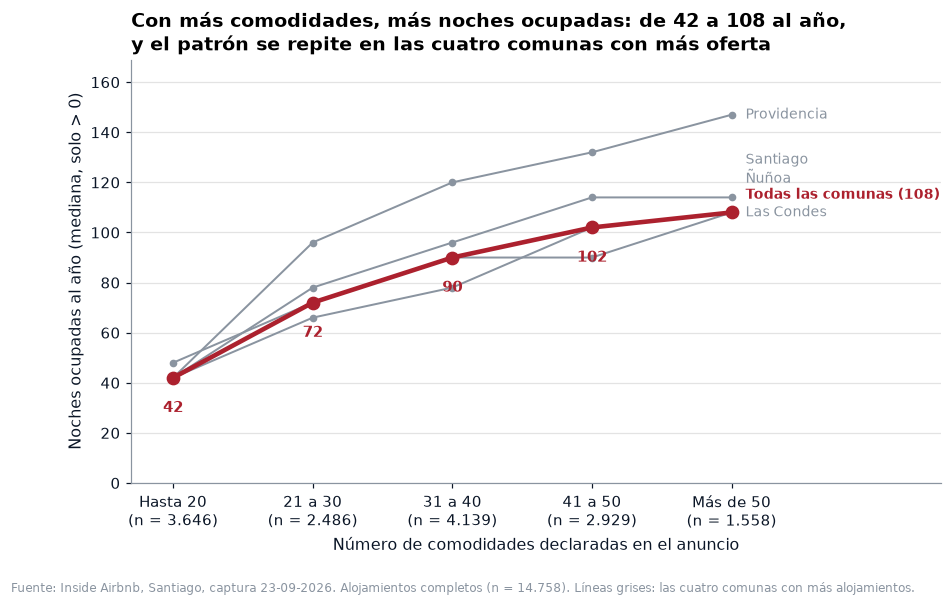

,n,ocupacion_mediana,pct_cero,precio_mediano
tramo_comodidades,,,,
Hasta 20,3646,42.0,0.39,54526.0
21 a 30,2486,72.0,0.16,56894.0
31 a 40,4139,90.0,0.10,60000.0
41 a 50,2929,102.0,0.08,63900.0
Más de 50,1558,108.0,0.08,72277.5


In [24]:
legible["tramo_comodidades"] = pd.cut(legible["n_comodidades"], bins=[-1, 20, 30, 40, 50, np.inf],
                                      labels=["Hasta 20", "21 a 30", "31 a 40", "41 a 50", "Más de 50"])
tramos = list(legible["tramo_comodidades"].cat.categories)
x = np.arange(len(tramos))
COMUNAS_GRANDES = legible["comuna"].value_counts().index[:4]

# Ocupación mediana por tramo: en todas las comunas y en cada una de las 4 más grandes
todas = legible.groupby("tramo_comodidades", observed=True)["ocupacion_positiva"].median()
por_comuna = (legible[legible["comuna"].isin(COMUNAS_GRANDES)]
              .groupby(["comuna", "tramo_comodidades"], observed=True)["ocupacion_positiva"].median()
              .unstack())

fig, eje = plt.subplots(figsize=(9.5, 5))
for comuna, fila in por_comuna.iterrows():                       # líneas grises: cada comuna
    eje.plot(x, fila.values, color=GRIS, linewidth=1.3, marker="o", markersize=4)
eje.plot(x, todas.values, color=GRANATE, linewidth=3, marker="o", markersize=8, zorder=3)
for xi, v in zip(x[:-1], todas.values[:-1]):
    eje.text(xi, v - 9, f"{v:.0f}", color=GRANATE, ha="center", va="top", fontsize=10, fontweight="bold")

# Etiquetas al final de cada línea, separadas para que no se tapen
etiquetas = [(fila.values[-1], comuna, GRIS, "normal") for comuna, fila in por_comuna.iterrows()]
etiquetas.append((todas.values[-1], f"Todas las comunas ({todas.values[-1]:.0f})", GRANATE, "bold"))
etiquetas.sort()
posiciones = []
for valor, *_ in etiquetas:
    posiciones.append(max(valor, posiciones[-1] + 7) if posiciones else valor)
for (valor, texto, color, peso), pos in zip(etiquetas, posiciones):
    eje.text(x[-1] + 0.1, pos, texto, color=color, fontsize=9, fontweight=peso, va="center")

n_tramo = legible["tramo_comodidades"].value_counts().reindex(tramos)
eje.set_xticks(x, [f"{t}\n(n = {miles(n)})" for t, n in zip(tramos, n_tramo)])
eje.set_xlim(-0.3, len(x) + 0.5)
eje.set_ylim(0, por_comuna.max().max() * 1.15)
eje.set_xlabel("Número de comodidades declaradas en el anuncio")
eje.set_ylabel("Noches ocupadas al año (mediana, solo > 0)")
eje.grid(axis="y", alpha=0.35)
eje.set_axisbelow(True)
eje.set_title(f"Con más comodidades, más noches ocupadas: de {todas.iloc[0]:.0f} a {todas.iloc[-1]:.0f} al año,\n"
              "y el patrón se repite en las cuatro comunas con más oferta", fontsize=12.5)
nota_fuente(fig, len(legible), "Líneas grises: las cuatro comunas con más alojamientos.")
plt.show()
figuras["fig3_comodidades"] = fig

# Tabla de la figura, con el precio y el % de ceros para el informe
g = legible.groupby("tramo_comodidades", observed=True)
tabla_fig3 = pd.DataFrame({"n": g.size(), "ocupacion_mediana": todas,
                           "pct_cero": g[OCUP].apply(lambda s: (s == 0).mean()),
                           "precio_mediano": g[PRECIO].median()})
tabla_fig3.round(2)

**Qué muestra.** La ocupación mediana (alojamientos con ocupación > 0) según cuántas comodidades declara el anuncio. La línea granate son todas las comunas; las grises, las cuatro comunas con más oferta por separado.

**Qué se infiere.** Los alojamientos con más comodidades se ocupan más: de 42 noches al año (hasta 20 comodidades) a 108 (más de 50). Además, el porcentaje con ocupación 0 cae de 39 % a 8 %. El patrón se repite dentro de Santiago, Providencia, Las Condes y Ñuñoa, así que no se explica por la ubicación. El precio, en cambio, sube poco: de $54.526 a $72.278.

**Qué límite tiene.** Es una asociación de una sola captura, no un efecto: agregar comodidades no garantiza más reservas. Un anuncio con más comodidades declaradas también puede reflejar un anfitrión más activo o profesional, que no se controla aquí.

**Cómo aporta al relato.** Es la resolución: la ubicación y la capacidad explican el **precio** (Figuras 1 y 2), mientras que las comodidades se asocian sobre todo a la **ocupación**.

### Figura 4 · Síntesis: capacidad y comodidades juntas

Se cruzan las dos variables que más se asocian a la ocupación: cuántos huéspedes admite el alojamiento y cuántas comodidades declara. Cada celda muestra la ocupación mediana (alojamientos con ocupación > 0) y cuántos alojamientos hay en ese grupo.

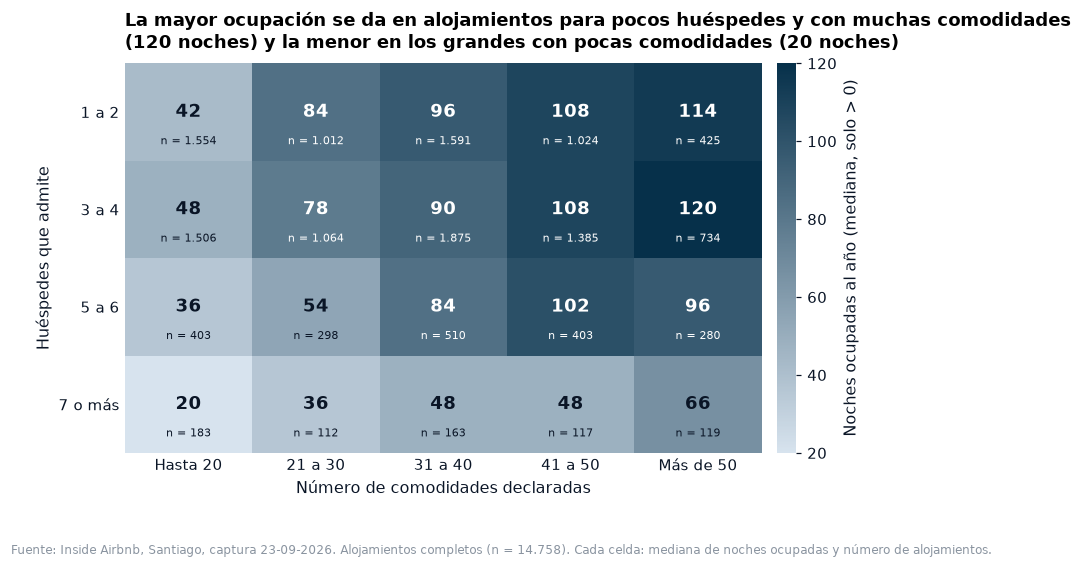

In [25]:
from matplotlib.colors import LinearSegmentedColormap

# Capacidad en 4 tramos para que la tabla no quede con celdas muy pequeñas
legible["capacidad_4"] = pd.cut(legible["accommodates"], bins=[0, 2, 4, 6, np.inf],
                                labels=["1 a 2", "3 a 4", "5 a 6", "7 o más"])
matriz = legible.pivot_table(index="capacidad_4", columns="tramo_comodidades",
                             values="ocupacion_positiva", aggfunc="median", observed=True)
conteos = legible.pivot_table(index="capacidad_4", columns="tramo_comodidades",
                              values=PRECIO, aggfunc="size", observed=True)

# Escala de un solo tono: claro = poca ocupación, oscuro = mucha
escala = LinearSegmentedColormap.from_list("hielo_azul", [HIELO, AZUL])

fig, eje = plt.subplots(figsize=(9, 4.6))
imagen = eje.imshow(matriz.values, cmap=escala, aspect="auto")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        valor = matriz.iat[i, j]
        color_texto = "white" if valor > matriz.values.mean() else TINTA   # legible sobre fondo oscuro
        eje.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=12, fontweight="bold", color=color_texto)
        eje.text(j, i + 0.3, f"n = {miles(conteos.iat[i, j])}", ha="center", va="center",
                 fontsize=7.5, color=color_texto)

eje.set_xticks(range(matriz.shape[1]), matriz.columns)
eje.set_yticks(range(matriz.shape[0]), matriz.index)
eje.set_xlabel("Número de comodidades declaradas")
eje.set_ylabel("Huéspedes que admite")
for lado in eje.spines.values():
    lado.set_visible(False)
eje.tick_params(length=0)
barra = fig.colorbar(imagen, ax=eje, pad=0.02)
barra.set_label("Noches ocupadas al año (mediana, solo > 0)")
barra.outline.set_visible(False)

eje.set_title(f"La mayor ocupación se da en alojamientos para pocos huéspedes y con muchas comodidades\n"
              f"({matriz.max().max():.0f} noches) y la menor en los grandes con pocas comodidades "
              f"({matriz.min().min():.0f} noches)", fontsize=12, pad=10)
nota_fuente(fig, len(legible), "Cada celda: mediana de noches ocupadas y número de alojamientos.")
plt.show()
figuras["fig4_sintesis"] = fig

**Qué muestra.** La ocupación mediana para cada combinación de capacidad y número de comodidades, con el número de alojamientos de cada grupo.

**Qué se infiere.** Las dos tendencias se suman. A igual capacidad, más comodidades se asocian a más ocupación: en 3 a 4 huéspedes, de 48 a 120 noches. A igual número de comodidades, los alojamientos para 7 o más huéspedes se ocupan menos que el resto. La combinación con mayor ocupación es 3 a 4 huéspedes con más de 50 comodidades (120 noches); la de menor, 7 o más huéspedes con hasta 20 comodidades (20 noches).

**Qué límite tiene.** Más ocupación no significa más ingreso: los alojamientos grandes cobran mucho más por noche (Figura 2). El análisis no incluye ingresos ni costos, y el alcance del proyecto excluye la rentabilidad. Es una asociación de una sola captura.

**Cómo aporta al relato.** Resume el hallazgo central: la capacidad se asocia al precio, y las comodidades a la ocupación.

--------
### Ojo
**Más ocupación no significa más ingreso**

In [26]:
# Ingreso anual estimado = precio publicado × noches ocupadas estimadas (incluye los ceros).
# Es una aproximación: no considera costos, descuentos ni el precio realmente pagado.
legible["ingreso_estimado"] = legible[PRECIO] * legible[OCUP]

tabla_ingreso = legible.groupby("capacidad_4", observed=True).agg(
    precio_mediano=(PRECIO, "median"),
    noches_medianas=("ocupacion_positiva", "median"),
    ingreso_anual_mediano=("ingreso_estimado", "median"),
)
tabla_ingreso.round(0)

,precio_mediano,noches_medianas,ingreso_anual_mediano
capacidad_4,,,
1 a 2,49500.0,84.0,2992179.0
3 a 4,60500.0,88.0,4146886.0
5 a 6,100234.0,72.0,6135000.0
7 o más,341062.0,42.0,8478456.0


Los alojamientos para 7 o más huéspedes se ocupan la mitad de noches que los de 1 a 2 (42 frente a 84), pero cobran unas 7 veces más por noche, así que su ingreso anual estimado es casi 3 veces mayor ($8,5 millones frente a $3,0 millones). Es una aproximación con precio publicado y ocupación estimada, sin costos: evaluar la rentabilidad queda fuera del alcance del proyecto y se propone como trabajo futuro.

### 3.5 Estabilidad de los hallazgos entre entrenamiento y prueba

**Qué cuenta como patrón estable:** que el **orden** de los grupos sea el mismo en ambos conjuntos. Por ejemplo, que las comunas más caras en entrenamiento también lo sean en prueba. Se mide con la correlación de Spearman entre la mediana de cada grupo en entrenamiento y en prueba: 1 significa el mismo orden; 0, ninguna relación. Solo se comparan grupos con al menos 10 alojamientos en cada conjunto.

In [27]:
def estabilidad(grupo, valor, minimo=10):
    """Spearman entre la mediana de cada grupo en entrenamiento y en prueba."""
    tabla = (legible.groupby([grupo, "conjunto"], observed=True)[valor]
             .agg(["median", "size"]).unstack("conjunto"))
    tabla = tabla[(tabla["size"] >= minimo).all(axis=1)]          # grupos con datos suficientes
    rho = tabla["median"]["entrenamiento"].corr(tabla["median"]["prueba"], method="spearman")
    return rho, len(tabla)


patrones = [
    ("Fig. 1 · Comunas ordenadas por precio mediano", "comuna", PRECIO),
    ("Fig. 1 · Comunas ordenadas por ocupación mediana", "comuna", "ocupacion_positiva"),
    ("Fig. 2 · Capacidad ordenada por precio mediano", "capacidad", PRECIO),
    ("Fig. 3 · Tramos de comodidades por ocupación mediana", "tramo_comodidades", "ocupacion_positiva"),
]
filas = []
for nombre, grupo, valor in patrones:
    rho, n = estabilidad(grupo, valor)
    filas.append({"patrón": nombre, "grupos comparados": n, "Spearman": round(rho, 2)})
tabla_estabilidad = pd.DataFrame(filas)
tabla_estabilidad

,patrón,grupos comparados,Spearman
0,Fig. 1 · Comunas ordenadas por precio mediano,17,0.88
1,Fig. 1 · Comunas ordenadas por ocupación mediana,17,0.88
2,Fig. 2 · Capacidad ordenada por precio mediano,7,1.00
3,Fig. 3 · Tramos de comodidades por ocupación m...,5,0.90


**Lectura.** Los cuatro patrones se repiten en ambos conjuntos: el orden de las comunas por precio y por ocupación (ρ = 0,88), el de la capacidad por precio (ρ = 1,00) y el de los tramos de comodidades por ocupación (ρ = 0,90). Los hallazgos no dependen de qué alojamientos quedaron en cada parte de la partición.

---
## 4. Una figura que miente, y cómo corregirla

El mismo dato puede contarse de forma honesta o engañosa. El caso más frecuente es el **eje truncado**: si el eje no empieza en cero, una diferencia pequeña parece enorme. El **factor de mentira** de Tufte lo cuantifica: el tamaño del efecto que se ve dividido por el tamaño del efecto real. Una figura honesta tiene un factor cercano a 1.

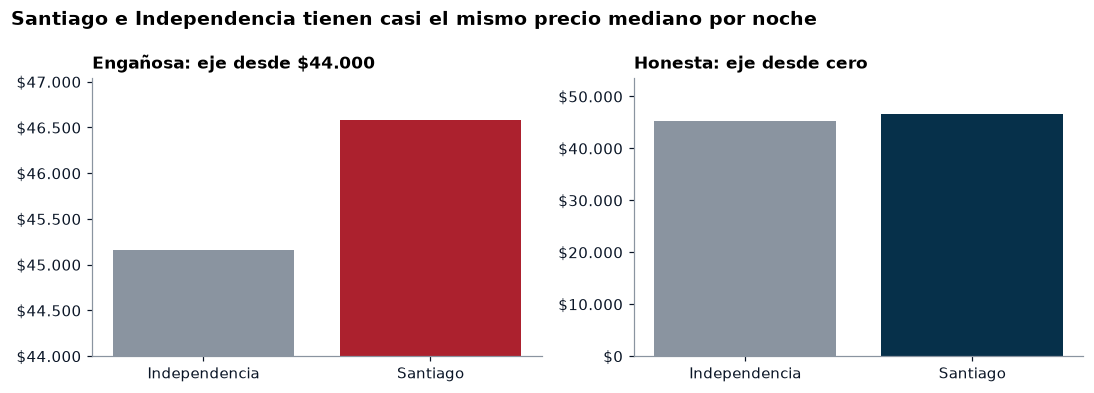

Diferencia real      : 3,1 %
Diferencia aparente  : 123 %
Factor de mentira    : 39


In [28]:
dos = legible.groupby("comuna")[PRECIO].median().loc[["Independencia", "Santiago"]]
valores = dos.to_numpy()
piso = 44_000          # el eje engañoso empieza aquí, no en cero

fig, (mal, bien) = plt.subplots(1, 2, figsize=(10, 3.6))
mal.bar(dos.index, valores, color=[GRIS, GRANATE])
mal.set_ylim(piso, valores.max() * 1.01)
mal.set_title(f"Engañosa: eje desde {clp(piso)}", fontsize=11)
bien.bar(dos.index, valores, color=[GRIS, AZUL])
bien.set_ylim(0, valores.max() * 1.15)
bien.set_title("Honesta: eje desde cero", fontsize=11)
for eje in (mal, bien):
    eje.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: clp(v)))
fig.suptitle("Santiago e Independencia tienen casi el mismo precio mediano por noche",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5)
plt.tight_layout()
plt.show()

efecto_real = valores.max() / valores.min() - 1
efecto_mostrado = (valores.max() - piso) / (valores.min() - piso) - 1
print(f"Diferencia real      : {pct(efecto_real, 1)}")
print(f"Diferencia aparente  : {pct(efecto_mostrado, 0)}")
print(f"Factor de mentira    : {efecto_mostrado / efecto_real:.0f}")

**Lectura.** La diferencia real es de 3,1 % ($46.577 frente a $45.158), pero con el eje desde $44.000 la barra de Santiago se ve más del doble de alta: un factor de mentira de 39. Por eso todas las figuras de magnitud de este cuaderno parten en cero. La excepción es el precio de la Figura 2, que usa escala logarítmica y lo declara en el eje, porque ahí se comparan proporciones y no diferencias absolutas.

---
## 5. Eficiencia: construir la copia interpretable

La Fase 3 midió el costo de sus transformaciones. Aquí se aplica la misma idea a la única operación nueva de esta fase, revertir el escalado, comparando un recorrido fila por fila con la operación vectorizada. Se usa la función `medir` de `src/medicion.py`, la misma de la Fase 3.

In [29]:
def revertir_fila_por_fila(df, parametros):
    """Versión ingenua: recorre cada valor en Python. Costo O(n · k)."""
    resultado = df.copy()
    for paso, valores in parametros.items():
        if paso.startswith("EscaladorRobusto("):
            columna = paso[len("EscaladorRobusto("):-1]
            resultado[columna] = [z * valores["ric"] + valores["mediana"] for z in resultado[columna]]
    return resultado


ingenua, t_ingenua, m_ingenua = medir(revertir_fila_por_fila, entrenamiento, parametros)
vectorizada, t_vector, m_vector = medir(com.revertir_escalamiento, entrenamiento, parametros)

pd.testing.assert_frame_equal(ingenua, vectorizada)   # mismo resultado, distinto costo
print(f"Fila por fila : {t_ingenua * 1000:8.2f} ms   pico {m_ingenua:6.2f} MB")
print(f"Vectorizada   : {t_vector * 1000:8.2f} ms   pico {m_vector:6.2f} MB")
print(f"La vectorizada es {t_ingenua / t_vector:.0f} veces más rápida, con el mismo resultado.")

Fila por fila :   128.63 ms   pico   9.04 MB
Vectorizada   :     6.39 ms   pico   9.03 MB
La vectorizada es 20 veces más rápida, con el mismo resultado.


Ambas versiones tienen complejidad lineal en el número de filas, O(n), pero la vectorizada ejecuta el recorrido en código compilado de NumPy en vez de en el intérprete de Python. Con 11.788 filas la diferencia es de milisegundos; con millones de registros sería la diferencia entre segundos y minutos. Por eso `copia_interpretable` usa la versión vectorizada. Los tiempos varían un poco en cada ejecución, pero la vectorizada siempre resulta varias veces más rápida.

---
## 6. Validación técnica

Tres escenarios, como pide el descriptor: casos normales, casos límite y excepciones. Cada control queda registrado en una tabla, que es la evidencia que se cita en el informe.

In [30]:
controles = []


def verificar(escenario, control, condicion, detalle=""):
    controles.append({"escenario": escenario, "control": control,
                      "estado": "OK" if condicion else "FALLA", "detalle": detalle})


# --- Casos normales: el flujo habitual produce lo esperado ---
verificar("normal", "La copia conserva las filas",
          len(entrenamiento_legible) == len(entrenamiento), f"{miles(len(entrenamiento_legible))} filas")
med_cap = parametros["EscaladorRobusto(accommodates)"]["mediana"]
verificar("normal", "La capacidad revertida tiene la mediana aprendida",
          np.isclose(entrenamiento_legible["accommodates"].median(), med_cap), f"{med_cap:.0f} huéspedes")
verificar("normal", "Los grupos de la Figura 1 suman todos los alojamientos",
          int(tabla_fig1["n"].sum()) == len(legible), miles(tabla_fig1["n"].sum()))

# --- Casos límite: las decisiones de la sección 3.1 se aplicaron bien ---
verificar("límite", "La ocupación positiva excluye exactamente los ceros",
          legible["ocupacion_positiva"].notna().sum() == (legible[OCUP] > 0).sum(),
          f"{miles(legible['ocupacion_positiva'].isna().sum())} ceros excluidos")
verificar("límite", "'Otras comunas' reúne solo las comunas con menos de 30",
          legible["comuna"].str.startswith("Otras").sum() == conteo[pequenas].sum(),
          f"{len(pequenas)} comunas, {miles(conteo[pequenas].sum())} alojamientos")
verificar("límite", "Ningún tramo de capacidad queda vacío",
          legible["capacidad"].value_counts().min() > 0,
          f"el menor tiene {legible['capacidad'].value_counts().min()} alojamientos")

# --- Excepciones: ante una entrada inválida, el código falla con un mensaje claro ---
try:
    com.cargar_artefactos(RAIZ / "carpeta_inexistente")
    verificar("excepción", "Falta un artefacto", False, "no lanzó error")
except FileNotFoundError:
    verificar("excepción", "Falta un artefacto", True, "FileNotFoundError")

try:
    com.leer_parametros(pd.DataFrame([{"paso": "EscaladorRobusto(accommodates)", "parametros": '{"mediana": '}]))
    verificar("excepción", "Parámetros con JSON incompleto", False, "no lanzó error")
except ValueError:
    verificar("excepción", "Parámetros con JSON incompleto", True, "ValueError")

try:
    resumen(legible, "columna_inexistente", PRECIO)
    verificar("excepción", "Agrupar por una columna inexistente", False, "no lanzó error")
except KeyError:
    verificar("excepción", "Agrupar por una columna inexistente", True, "KeyError")

tabla_controles = pd.DataFrame(controles)
assert (tabla_controles["estado"] == "OK").all(), "Hay controles que fallaron"
tabla_controles

,escenario,control,estado,detalle
0,normal,La copia conserva las filas,OK,11.788 filas
1,normal,La capacidad revertida tiene la mediana aprendida,OK,3 huéspedes
2,normal,Los grupos de la Figura 1 suman todos los aloj...,OK,14.758
3,límite,La ocupación positiva excluye exactamente los ...,OK,2.599 ceros excluidos
4,límite,'Otras comunas' reúne solo las comunas con men...,OK,"12 comunas, 120 alojamientos"
5,límite,Ningún tramo de capacidad queda vacío,OK,el menor tiene 65 alojamientos
6,excepción,Falta un artefacto,OK,FileNotFoundError
7,excepción,Parámetros con JSON incompleto,OK,ValueError
8,excepción,Agrupar por una columna inexistente,OK,KeyError


---
## 7. Anexos

Figuras y tablas complementarias. No forman parte del relato principal, pero respaldan las decisiones del análisis y permiten revisar el detalle.

---
## 8. Persistencia: lo que se lleva al informe y al video

Las figuras se guardan en `F4/figuras/` a 200 ppp. Los hallazgos se guardan en `docs/hallazgos_f4.csv`, con la cifra exacta y la sección que la produce: así el informe y el video se escriben desde la misma fuente.

In [35]:
rutas = {nombre: com.guardar_figura(figura, DIR_FIGURAS, nombre) for nombre, figura in figuras.items()}

# Las cifras se toman de las tablas de cada figura, no se escriben a mano
t1 = tabla_fig1.drop(index=[c for c in tabla_fig1.index if c.startswith("Otras")]).sort_values(
    "precio_mediano", ascending=False)
c1 = t1.index[0]
hallazgos = pd.DataFrame([
    {"seccion": "3.1", "figura": "-", "hallazgo": "Precio y ocupación medianos",
     "evidencia": f"{clp(legible[PRECIO].median())} por noche; {legible[OCUP].median():.0f} noches al año"},
    {"seccion": "3.1", "figura": "anexo1_distribuciones", "hallazgo": "Ocupación con ceros y tope",
     "evidencia": f"{pct(ceros)} con 0 noches; {pct(en_tope)} en el tope de {TOPE:.0f}"},
    {"seccion": "Figura 1", "figura": "fig1_ubicacion", "hallazgo": "La comuna más cara no es la más ocupada",
     "evidencia": f"{c1}: {clp(t1.loc[c1, 'precio_mediano'])} y {t1.loc[c1, 'ocupacion_mediana']:.0f} noches; "
                  f"Providencia: {clp(t1.loc['Providencia', 'precio_mediano'])} y "
                  f"{t1.loc['Providencia', 'ocupacion_mediana']:.0f} noches"},
    {"seccion": "Figura 2", "figura": "fig2_capacidad", "hallazgo": "El precio sube con la capacidad y la ocupación baja",
     "evidencia": f"2 huéspedes: {clp(tabla_fig2['precio_mediano'].iloc[1])} y {tabla_fig2['ocupacion_mediana'].iloc[1]:.0f} noches; "
                  f"9 o más: {clp(tabla_fig2['precio_mediano'].iloc[-1])} y {tabla_fig2['ocupacion_mediana'].iloc[-1]:.0f} noches"},
    {"seccion": "Figura 3", "figura": "fig3_comodidades", "hallazgo": "Más comodidades, más ocupación, también dentro de cada comuna",
     "evidencia": f"De {tabla_fig3['ocupacion_mediana'].iloc[0]:.0f} a {tabla_fig3['ocupacion_mediana'].iloc[-1]:.0f} noches; "
                  f"ocupación 0 de {pct(tabla_fig3['pct_cero'].iloc[0], 0)} a {pct(tabla_fig3['pct_cero'].iloc[-1], 0)}"},
    {"seccion": "Figura 4", "figura": "fig4_sintesis", "hallazgo": "Mayor ocupación: pocos huéspedes y muchas comodidades",
     "evidencia": f"Máximo {matriz.max().max():.0f} noches; mínimo {matriz.min().min():.0f} noches"},
    {"seccion": "Figura 4", "figura": "-", "hallazgo": "Más ocupación no significa más ingreso",
     "evidencia": f"Ingreso anual estimado: {clp(tabla_ingreso['ingreso_anual_mediano'].iloc[0])} (1 a 2 huéspedes) "
                  f"frente a {clp(tabla_ingreso['ingreso_anual_mediano'].iloc[-1])} (7 o más)"},
    {"seccion": "3.5", "figura": "-", "hallazgo": "Los patrones se repiten en entrenamiento y prueba",
     "evidencia": "Spearman entre " + " y ".join(f"{v:.2f}".replace(".", ",") for v in
                  [tabla_estabilidad["Spearman"].min(), tabla_estabilidad["Spearman"].max()])},
])
hallazgos.to_csv(DIR_DOCS / "hallazgos_f4.csv", index=False)

metadatos = {
    "fase": "F4",
    "fecha_ejecucion": date.today().isoformat(),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "dependencias": {"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "entradas": sorted(str(p.relative_to(RAIZ)) for p in DIR_PROCESADO.glob("*_f3.csv")),
    "figuras": [str(Path(r).relative_to(RAIZ)) for r in rutas.values()],
    "controles_superados": int((tabla_controles["estado"] == "OK").sum()),
}
with open(DIR_DOCS / "metadatos_f4.json", "w", encoding="utf-8") as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)

# Rutas relativas: no se muestra la carpeta personal
for nombre, ruta in rutas.items():
    print(f"{nombre:<34} {Path(ruta).relative_to(RAIZ)}  ({os.path.getsize(ruta) / 1024:.0f} KB)")
print("\nHallazgos :", (DIR_DOCS / "hallazgos_f4.csv").relative_to(RAIZ))
print("Metadatos :", (DIR_DOCS / "metadatos_f4.json").relative_to(RAIZ))
hallazgos

fig1_ubicacion                     F4\figuras\fig1_ubicacion.png  (185 KB)
fig2_capacidad                     F4\figuras\fig2_capacidad.png  (129 KB)
fig3_comodidades                   F4\figuras\fig3_comodidades.png  (161 KB)
fig4_sintesis                      F4\figuras\fig4_sintesis.png  (152 KB)
anexo1_distribuciones              F4\figuras\anexo1_distribuciones.png  (122 KB)
anexo2_comodidades_con_sin         F4\figuras\anexo2_comodidades_con_sin.png  (173 KB)
anexo3_comodidades_por_anfitrion   F4\figuras\anexo3_comodidades_por_anfitrion.png  (144 KB)
anexo4_correlaciones               F4\figuras\anexo4_correlaciones.png  (162 KB)

Hallazgos : docs\hallazgos_f4.csv
Metadatos : docs\metadatos_f4.json


,seccion,figura,hallazgo,evidencia
0,3.1,-,Precio y ocupación medianos,$60.000 por noche; 60 noches al año
1,3.1,anexo1_distribuciones,Ocupación con ceros y tope,"17,6 % con 0 noches; 10,5 % en el tope de 255"
2,Figura 1,fig1_ubicacion,La comuna más cara no es la más ocupada,Lo Barnechea: $391.834 y 32 noches; Providenci...
3,Figura 2,fig2_capacidad,El precio sube con la capacidad y la ocupación...,2 huéspedes: $49.767 y 84 noches; 9 o más: $42...
4,Figura 3,fig3_comodidades,"Más comodidades, más ocupación, también dentro...",De 42 a 108 noches; ocupación 0 de 39 % a 8 %
5,Figura 4,fig4_sintesis,Mayor ocupación: pocos huéspedes y muchas como...,Máximo 120 noches; mínimo 20 noches
6,Figura 4,-,Más ocupación no significa más ingreso,Ingreso anual estimado: $2.992.179 (1 a 2 hués...
7,3.5,-,Los patrones se repiten en entrenamiento y prueba,"Spearman entre 0,88 y 1,00"


---
## 9. El relato en tres actos

El informe y el video cuentan lo mismo, en este orden:

**Acto 1 · Contexto (Figura 1).** El precio de los alojamientos completos de Santiago depende mucho de la ubicación: Lo Barnechea cobra unas 8,4 veces lo que Santiago. Pero las comunas más caras no son las más ocupadas: Providencia e Independencia, con precios intermedios, llegan a 108 noches al año.

**Acto 2 · Contraste (Figura 2).** Lo que sube el precio no sube la ocupación. Los alojamientos para 9 o más huéspedes cobran unas 8,5 veces más que los de 2, pero se ocupan 54 noches menos.

**Acto 3 · Resolución (Figuras 3 y 4).** Las comodidades se asocian a la ocupación más que al precio: de 42 a 108 noches al año entre los alojamientos con menos y más comodidades, y el patrón se repite dentro de cada comuna grande y en ambos tipos de anfitrión. La mayor ocupación se da en alojamientos para pocos huéspedes y bien equipados. Aun así, más ocupación no significa más ingreso: los alojamientos grandes ingresan más porque cobran mucho más por noche.

**En una frase:** la ubicación y la capacidad se asocian al precio; las comodidades, a la ocupación.

### Limitaciones que el informe debe declarar

1. **Precio publicado**, no precio pagado: no incluye descuentos ni variaciones por temporada.
2. **Ocupación estimada** a partir de las reseñas, con 17,6 % de ceros y 10,5 % en el tope de 255 noches; no es la ocupación real.
3. **Una sola captura** (23-09-2026): no permite ver estacionalidad ni cambios en el tiempo.
4. **Supervivencia de anuncios:** solo aparecen los alojamientos activos en la fecha de captura.
5. **Asociación, no causalidad:** es un corte transversal. Ninguna figura demuestra que agregar una comodidad produzca más reservas.
6. **Sin ingresos reales ni costos:** el ingreso estimado es una aproximación, y la rentabilidad queda fuera del alcance (trabajo futuro).